# Pipeline 01: Ingesta de Alertas Rubin DP1, Censo de Variabilidad y Crossmatch Taxonómico con Gaia DR3
## Fase 1: Ingesta Masiva, Filtrado Instrumental y Caracterización Astrométrica

Este cuaderno implementa la **primera etapa fundamental** del pipeline astrofísico sobre el conjunto de alertas **`umbramortem/alerts_open_tools_open_sky_2026`** (Data Preview 1 del Observatorio Vera C. Rubin).

A partir de las tablas masivas en formato Parquet, se realiza la ingesta relacional en DuckDB, el censo de fuentes variables mediante indicadores fotométricos propios de Rubin, la resolución astrométrica con Fink/LSST, y la clasificación taxonómica unívoca mediante crossmatch espacial y cinemático con **Gaia DR3**.

### Objetivos y Arquitectura de la Fase 1:
1. **Ingesta Estructurada en DuckDB:** Conexión y creación de vistas optimizadas en memoria (`:memory:`) respetando la arquitectura de tres niveles de Rubin:
   - `v_objects`: Resumen a nivel de objeto estelar (`diaObject`).
   - `v_detections`: Detecciones en imágenes de diferencia (`diaSource`) que superan el umbral de alerta.
   - `v_forced`: Fotometría PSF forzada en las coordenadas del objeto, indispensable para registrar mínimos de brillo.
2. **Censo Físico de Variabilidad Intrínseca:** Filtrado instrumental de artefactos (dipolos de resta, saturación, rayos cósmicos, trazas de satélites); cálculo de varianza reducida $\chi^2_{\text{red}} \ge 3.0$ y amplitud fraccional robusta $\ge 5\%$.
   - **Salida 1:** Genera el catálogo preliminar `rubin_variable_candidates.csv` (1,920 candidatos).
3. **Resolución Astrométrica y Crossmatch con Gaia DR3:**
   - Recuperación de coordenadas ICRS (`ra`, `dec`) mediante la API oficial de **Fink/LSST**.
   - Propagación cinemática de movimiento propio desde la época J2016.0 de Gaia hasta la época de observación de Rubin (MJD 61100.0).
   - Consulta ADQL espacial en el archivo TAP de Gaia DR3 con cono de búsqueda de $1.5''$.
   - Clasificación taxonómica multivariada y aislamiento de las candelas estándar (**RR Lyrae**).
   - **Salida 2:** Genera el catálogo maestro consolidado `rubin_gaia_crossmatch.csv` (1,920 variables cruzadas y clasificadas).
4. **Diagnóstico Demográfico Visual:** Visualización de la distribución taxonómica y el espacio magnitud-amplitud de Rubin DP1.


In [1]:
# ==============================================================================
# CONFIGURACIÓN DEL ENTORNO, IMPORTS Y CONTROL DE EJECUCIÓN (FASE 1)
# ==============================================================================
import os
import sys
import json
import warnings
from pathlib import Path
from time import perf_counter
from concurrent.futures import ThreadPoolExecutor

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

try:
    import duckdb
except ImportError:
    duckdb = None

try:
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from astropy.time import Time
    from astropy.table import Table
except ImportError:
    u = SkyCoord = Time = Table = None

try:
    from astroquery.gaia import Gaia
except ImportError:
    Gaia = None

try:
    from huggingface_hub import snapshot_download
except ImportError:
    snapshot_download = None

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

# ==============================================================================
# MODO RÁPIDO Y PERSISTENCIA LOCAL (OFFLINE CACHE / RE-USO DE ARCHIVOS)
# ==============================================================================
# True  = Carga directamente los catálogos locales precalculados (.csv) en < 0.1 s,
#         evitando re-descargar de HuggingFace o re-consultar Fink y Gaia TAP.
# False = Obliga a re-ejecutar las consultas pesadas desde cero y re-generar los archivos.
USE_LOCAL_CACHE = True

# Control de muestra para pruebas
USE_SAMPLE_LIMIT = False
SAMPLE_LIMIT = 400

# Parámetros del repositorio remoto
REPO_ID = "umbramortem/alerts_open_tools_open_sky_2026"
REPO_TYPE = "dataset"
REVISION = "main"

# Parámetros físicos de selección de variabilidad en Rubin
MIN_CLEAN_DETECTIONS = 10      # Mínimo de detecciones limpias por objeto
MIN_BANDS = 2                  # Mínimo de filtros distintos de Rubin (u,g,r,i,z,y)
MIN_BASELINE_DAYS = 3.0        # Línea base temporal mínima [días]
MIN_RELIABILITY = 0.5          # Umbral de confiabilidad real/bogus en DIA
MIN_SCIENCEFLUX_NJY = 10000.0  # Flujo total mediano mínimo [nJy] (~21.4 mag AB)
MIN_REDUCED_CHI2 = 3.0         # Significancia estadística de variabilidad respecto a flujo constante
MIN_FRAC_AMP90 = 0.05          # Amplitud intercuantil (P95 - P05) / med_flux >= 5%

# Configuración de recursos para DuckDB
DUCKDB_THREADS = max(2, (os.cpu_count() or 2))
DUCKDB_MEMORY_LIMIT = "8GB"
DUCKDB_TEMP_DIRECTORY = "duckdb_temp"

try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

print(f"Entorno inicializado correctamente para Fase 1 (Ingesta y Censo).")
print(f"DuckDB: {duckdb.__version__ if duckdb is not None else 'No instalado (Modo Caché Activo)'}")
print(f"Modo de Caché Local Activo: {USE_LOCAL_CACHE}")
print(f"Modo de Selección: {'MUESTRA LIMITADA (' + str(SAMPLE_LIMIT) + ')' if USE_SAMPLE_LIMIT else 'CENSO COMPLETO (1,920 variables)'}")


Entorno inicializado correctamente para Fase 1 (Ingesta y Censo).
DuckDB: No instalado (Modo Caché Activo)
Modo de Caché Local Activo: True
Modo de Selección: CENSO COMPLETO (1,920 variables)


## Bloque 1: Ingesta Estructurada de `umbramortem` en DuckDB

Se inicializa la arquitectura de tres niveles de alertas de Rubin utilizando **DuckDB** en memoria (`:memory:`) para aprovechar la vectorización SIMD nativa sobre Parquet:

1. **`v_objects` (`XRUBIN_raw_all/objects/*.parquet`):** Catálogo a nivel de objeto estelar (`diaObject`), con métricas globales consolidadas.
2. **`v_detections` (`XRUBIN_raw_all/detections/*.parquet`):** Detecciones en imágenes de diferencia (`diaSource`) que superaron el umbral de alerta.
3. **`v_forced` (`XRUBIN_raw_all/forced/*.parquet`):** Fotometría forzada PSF en las coordenadas del objeto, indispensable para registrar las fases de brillo mínimo.

> [!NOTE]
> Si `USE_LOCAL_CACHE = True` y los catálogos consolidados existen en disco, el pipeline utiliza la ruta rápida instantánea (< 0.1 s), preservando toda la lógica de ingesta en la rama `else:`.


In [3]:
# ==============================================================================
# BLOQUE 1: INGESTA ESTRUCTURADA DE ALERTAS EN DUCKDB
# ==============================================================================
CACHE_CAND_CSV = Path("rubin_variable_candidates.csv")
CACHE_XM_CSV = Path("rubin_gaia_crossmatch.csv")

if USE_LOCAL_CACHE and CACHE_XM_CSV.exists() and CACHE_CAND_CSV.exists():
    print("=" * 80)
    print("[MODO RÁPIDO / CACHÉ LOCAL DETECTADA]")
    print(f"Se detectaron los archivos de datos consolidados de Fase 1:")
    print(f"  -> {CACHE_CAND_CSV} ({CACHE_CAND_CSV.stat().st_size / 1024:.1f} KB)")
    print(f"  -> {CACHE_XM_CSV} ({CACHE_XM_CSV.stat().st_size / 1024:.1f} KB)")
    print("Omitiendo la descarga masiva de Hugging Face y la ingesta pesada en DuckDB.")
    print("-> Para forzar la re-descarga y re-procesamiento completo, fijar USE_LOCAL_CACHE = False en la Celda 1.")
    print("=" * 80)
    con = None
else:
    t0 = perf_counter()
    print(f"Sincronizando Parquet desde {REPO_ID} en Hugging Face...")
    local_dataset_directory = Path(
        snapshot_download(
            repo_id=REPO_ID,
            repo_type=REPO_TYPE,
            revision=REVISION,
            token=HF_TOKEN,
            allow_patterns=["*.parquet", "**/*.parquet"],
        )
    )

    objects_files = sorted((local_dataset_directory / "XRUBIN_raw_all" / "objects").glob("*.parquet"))
    detections_files = sorted((local_dataset_directory / "XRUBIN_raw_all" / "detections").glob("*.parquet"))
    forced_files = sorted((local_dataset_directory / "XRUBIN_raw_all" / "forced").glob("*.parquet"))

    print(f"Archivos encontrados en disco ({perf_counter() - t0:.1f} s):")
    print(f" - objects/    : {len(objects_files):,}")
    print(f" - detections/ : {len(detections_files):,}")
    print(f" - forced/     : {len(forced_files):,}")

    if not objects_files or not detections_files:
        raise FileNotFoundError("Faltan archivos Parquet esenciales en objects/ o detections/.")

    # Conexión optimizada única a DuckDB en memoria
    con = duckdb.connect(database=":memory:")
    con.execute(f"PRAGMA threads={DUCKDB_THREADS};")
    con.execute(f"PRAGMA memory_limit='{DUCKDB_MEMORY_LIMIT}';")
    Path(DUCKDB_TEMP_DIRECTORY).mkdir(exist_ok=True)
    con.execute(f"PRAGMA temp_directory='{DUCKDB_TEMP_DIRECTORY}';")
    con.execute("SET preserve_insertion_order = false;")

    objects_glob = str(local_dataset_directory / "XRUBIN_raw_all" / "objects" / "*.parquet")
    det_glob = str(local_dataset_directory / "XRUBIN_raw_all" / "detections" / "*.parquet")
    forced_glob = str(local_dataset_directory / "XRUBIN_raw_all" / "forced" / "*.parquet")

    con.execute(f"CREATE OR REPLACE VIEW v_objects AS SELECT * FROM read_parquet('{objects_glob}', union_by_name=true);")
    con.execute(f"CREATE OR REPLACE VIEW v_detections AS SELECT * FROM read_parquet('{det_glob}', union_by_name=true);")
    con.execute(f"CREATE OR REPLACE VIEW v_forced AS SELECT * FROM read_parquet('{forced_glob}', union_by_name=true);")

    print("\nEsquema verificado exitosamente en DuckDB para las 3 vistas de Rubin.")


[MODO RÁPIDO / CACHÉ LOCAL DETECTADA]
Se detectaron los archivos de datos consolidados de Fase 1:
  -> rubin_variable_candidates.csv (432.8 KB)
  -> rubin_gaia_crossmatch.csv (988.9 KB)
Omitiendo la descarga masiva de Hugging Face y la ingesta pesada en DuckDB.
-> Para forzar la re-descarga y re-procesamiento completo, fijar USE_LOCAL_CACHE = False en la Celda 1.


## Bloque 2: Censo Completo de Variabilidad en Rubin

Seleccionamos candidatos a estrellas variables utilizando **exclusivamente indicadores fotométricos de Rubin** sobre `v_detections` y `v_objects`:

1. **Higiene instrumental por época:** Descartamos detecciones afectadas por dipolos de resta (`NOT isdipole`), píxeles defectuosos (`NOT pixelflags_bad`), saturación (`NOT pixelflags_saturated`), rayos cósmicos (`NOT pixelflags_cr`), trazas de satélites o fantasmas ópticos (`NOT pixelflags_streak`, `NOT glint_trail`) y baja confiabilidad del clasificador (`reliability > 0.5`).
2. **Consistencia estadística y cobertura temporal:**
   - Al menos 10 épocas limpias por estrella (`n_clean_det >= 10`).
   - Muestreo en al menos 2 filtros fotométricos distintos (`n_bands >= 2`).
   - Línea base temporal $\ge 3.0\text{ días}$.
   - Nivel de flujo mediano superior a $10{,}000\text{ nJy}$ ($m_{\text{AB}} \lesssim 21.4\text{ mag}$).
3. **Significancia de la variabilidad física:**
   - Varianza reducida normalizada frente a flujo constante:
     $$\chi^2_{\text{red}} = \frac{1}{N - 1} \sum_{i=1}^N \frac{(F_i - \bar{F})^2}{\sigma_{F,i}^2} \ge 3.0$$
   - Amplitud fraccional robusta intercuantil:
     $$\frac{\Delta F_{90}}{F_{\text{med}}} = \frac{Q_{95}(F) - Q_{05}(F)}{F_{\text{med}}} \ge 0.05 \quad (5\%)$$

Los objetos que superan este filtro se consolidan en `rubin_variable_candidates.csv`.


In [5]:
# ==============================================================================
# BLOQUE 2: CENSO FÍSICO DE VARIABILIDAD EN DUCKDB
# ==============================================================================
t0 = perf_counter()
CAND_CSV = Path("rubin_variable_candidates.csv")
CACHE_XM_CSV = Path("rubin_gaia_crossmatch.csv")

if USE_LOCAL_CACHE and (CAND_CSV.exists() or CACHE_XM_CSV.exists()):
    if CAND_CSV.exists():
        rubin_variable_candidates_df = pd.read_csv(CAND_CSV)
    else:
        df_xm_raw = pd.read_csv(CACHE_XM_CSV)
        cand_cols = [
            "oid", "rubin_oid_str", "ndiasources", "n_clean_det", "n_bands",
            "first_mjd", "last_mjd", "baseline_days", "med_scienceflux",
            "rubin_approx_mag", "rubin_frac_amp", "rubin_approx_amp_mag",
            "reduced_chi2", "flux_skewness", "med_snr"
        ]
        rubin_variable_candidates_df = df_xm_raw[[c for c in cand_cols if c in df_xm_raw.columns]].drop_duplicates("oid").reset_index(drop=True)

    print(f"[MODO RÁPIDO / CACHÉ LOCAL] Candidatos de variabilidad cargados desde {CAND_CSV.name} en {perf_counter() - t0:.3f} s.")
    print(f" -> Total de objetos candidatos a variables: {len(rubin_variable_candidates_df):,}")
else:
    limit_clause = f"LIMIT {int(SAMPLE_LIMIT)}" if USE_SAMPLE_LIMIT else ""

    variability_census_sql = f'''
    WITH clean_det AS (
        SELECT
            oid,
            mjd,
            band_name,
            CAST(scienceflux AS DOUBLE) AS scienceflux,
            CAST(sciencefluxerr AS DOUBLE) AS sciencefluxerr,
            CAST(psfflux AS DOUBLE) AS psfflux,
            CAST(psffluxerr AS DOUBLE) AS psffluxerr,
            CAST(snr AS DOUBLE) AS snr,
            CAST(reliability AS DOUBLE) AS reliability
        FROM v_detections
        WHERE oid IS NOT NULL
          AND scienceflux IS NOT NULL
          AND scienceflux > 0
          AND sciencefluxerr > 0
          AND NOT COALESCE(isdipole, FALSE)
          AND NOT COALESCE(pixelflags_bad, FALSE)
          AND NOT COALESCE(pixelflags_saturated, FALSE)
          AND NOT COALESCE(pixelflags_cr, FALSE)
          AND NOT COALESCE(pixelflags_streak, FALSE)
          AND NOT COALESCE(glint_trail, FALSE)
          AND COALESCE(reliability, 1.0) > {float(MIN_RELIABILITY)}
    ),
    mean_per_obj AS (
        SELECT
            oid,
            AVG(scienceflux) AS mean_sci_flux
        FROM clean_det
        GROUP BY oid
        HAVING COUNT(*) >= {int(MIN_CLEAN_DETECTIONS)}
           AND COUNT(DISTINCT band_name) >= {int(MIN_BANDS)}
           AND (MAX(mjd) - MIN(mjd)) >= {float(MIN_BASELINE_DAYS)}
           AND MEDIAN(scienceflux) >= {float(MIN_SCIENCEFLUX_NJY)}
    ),
    agg_metrics AS (
        SELECT
            d.oid,
            COUNT(*) AS n_clean_det,
            COUNT(DISTINCT d.band_name) AS n_bands,
            MIN(d.mjd) AS first_mjd,
            MAX(d.mjd) AS last_mjd,
            MAX(d.mjd) - MIN(d.mjd) AS baseline_days,
            MEDIAN(d.scienceflux) AS med_scienceflux,
            AVG(d.scienceflux) AS mean_scienceflux,
            STDDEV_SAMP(d.scienceflux) AS std_scienceflux,
            (QUANTILE_CONT(d.scienceflux, 0.95) - QUANTILE_CONT(d.scienceflux, 0.05)) AS amp_scienceflux_90,
            SUM(POWER((d.scienceflux - m.mean_sci_flux) / d.sciencefluxerr, 2)) / NULLIF(COUNT(*) - 1, 0) AS reduced_chi2,
            SKEWNESS(d.scienceflux) AS flux_skewness,
            MEDIAN(d.snr) AS med_snr,
            AVG(d.reliability) AS mean_reliability
        FROM clean_det d
        INNER JOIN mean_per_obj m ON d.oid = m.oid
        GROUP BY d.oid
    )
    SELECT
        a.oid,
        CAST(a.oid AS VARCHAR) AS rubin_oid_str,
        o.ndiasources,
        a.n_clean_det,
        a.n_bands,
        a.first_mjd,
        a.last_mjd,
        a.baseline_days,
        a.med_scienceflux,
        -2.5 * LOG10(a.med_scienceflux / 1e9 / 3631.0) AS rubin_approx_mag,
        a.amp_scienceflux_90 / NULLIF(a.med_scienceflux, 0) AS rubin_frac_amp,
        2.5 * LOG10(1.0 + (a.amp_scienceflux_90 / NULLIF(a.med_scienceflux, 0))) AS rubin_approx_amp_mag,
        a.reduced_chi2,
        COALESCE(a.flux_skewness, 0.0) AS flux_skewness,
        a.med_snr,
        a.mean_reliability
    FROM agg_metrics a
    LEFT JOIN v_objects o ON a.oid = o.oid
    WHERE a.reduced_chi2 >= {float(MIN_REDUCED_CHI2)}
      AND (a.amp_scienceflux_90 / NULLIF(a.med_scienceflux, 0)) BETWEEN {float(MIN_FRAC_AMP90)} AND 5.0
    ORDER BY a.med_snr * (a.amp_scienceflux_90 / NULLIF(a.med_scienceflux, 0)) DESC
    {limit_clause}
    '''

    print("Ejecutando censo físico de variabilidad en DuckDB...")
    rubin_variable_candidates_df = con.execute(variability_census_sql).df()
    print(f"Censo completado en {perf_counter() - t0:.1f} s: {len(rubin_variable_candidates_df):,} candidatos variables.")
    rubin_variable_candidates_df.to_csv(CAND_CSV, index=False)
    print(f" -> Guardado exitosamente en {CAND_CSV.name}")

print("\nMuestra de los primeros 5 candidatos variables seleccionados:")
display_cols = ["oid", "n_clean_det", "n_bands", "baseline_days", "rubin_approx_mag", "rubin_frac_amp", "reduced_chi2"]
display(rubin_variable_candidates_df[display_cols].head(5))


[MODO RÁPIDO / CACHÉ LOCAL] Candidatos de variabilidad cargados desde rubin_variable_candidates.csv en 0.007 s.
 -> Total de objetos candidatos a variables: 1,920

Muestra de los primeros 5 candidatos variables seleccionados:
                  oid  n_clean_det  n_bands  baseline_days  rubin_approx_mag  \
0  170032883710820486           18        2     144.336723         15.515133   
1  313967765858287672           57        2     155.819766         15.903696   
2  313871013097505003          157        5     177.668659         16.845559   
3  314003014107006318           61        6      68.960918         18.528418   
4  313831458605105176          110        4     216.126620         16.087769   

   rubin_frac_amp   reduced_chi2  
0        2.113684  709567.046343  
1        2.425786  259328.720218  
2        1.779089   98344.812291  
3        3.677825   84225.013603  
4        2.351713  708128.664885  


## Bloque 3: Funciones de Resolución Astrométrica y Clasificación Taxonómica

Para vincular las alertas de Rubin con fuentes astronómicas de referencia:
1. **Resolución Astrométrica:** Consultamos la API oficial de **Fink/LSST** (`https://api.lsst.fink-portal.org/api/v1/sources`) mediante peticiones concurrentes por lotes con reintentos defensivos.
2. **Clasificación Taxonómica Multivariada:** Implementamos la función `classify_stellar_variability`, que jerarquiza:
   - Descarte extragaláctico (`AGN`, `QSO`, `prob_quasar > 0.5`).
   - Identificación de **RR Lyrae** (`RR`, `RRAB`, `RRC`, `RRD`) en clasificadores de Gaia DR3 (`vari_classifier_result`, `vari_rrlyrae`), VSX, GCVS y SIMBAD.
   - Detección de Cefeidas, Delta Scuti, Binarias Eclipsantes, Variables Rotacionales y Eruptivas.
   - Asignación de estrellas variables de campo estelares de Rubin (`Otras Estrellas Rubin`) confirmadas por astrometría (`parallax_over_error > 3.0` o `pm > 5 mas/yr` o `prob_star > 0.8`).


In [7]:
# ==============================================================================
# BLOQUE 3: FUNCIONES DE RESOLUCIÓN ASTROMÉTRICA Y CLASIFICACIÓN TAXONÓMICA
# ==============================================================================
session = requests.Session()

def fetch_fink_batch(chunk):
    '''Consulta coordenadas y metadatos preliminares para un lote de diaObjectIds en Fink API.'''
    url = "https://api.lsst.fink-portal.org/api/v1/sources"
    payload = {
        "diaObjectId": ",".join(chunk),
        "columns": (
            "r:diaObjectId,r:ra,r:dec,"
            "f:xm_gaiadr3_DR3Name,f:xm_gaiadr3_VarFlag,"
            "f:xm_vsx_Type,f:xm_gcvs_type,f:xm_simbad_otype,f:clf_cats_class"
        ),
        "output-format": "json",
    }
    for attempt in range(3):
        try:
            r = session.post(url, json=payload, timeout=25)
            if r.status_code == 200 and r.text.strip():
                data = r.json()
                if isinstance(data, list) and len(data) > 0:
                    df_c = pd.DataFrame(data)
                    df_c.columns = [c.split(":")[-1] for c in df_c.columns]
                    return df_c.groupby("diaObjectId", as_index=False).first()
            break
        except Exception:
            continue
    return pd.DataFrame()


extragalactic_tags = {"AGN", "QSO", "SY1", "SY2", "G", "RG", "BCG", "BLL", "BLAZAR", "LIN", "GALAXY"}

def classify_stellar_variability(row):
    '''Clasifica taxonómicamente cada objeto integrando Gaia DR3, VSX, GCVS y SIMBAD.'''
    g_cls = str(row.get("gaia_var_class", "") or "").strip().upper()
    vsx_cls = str(row.get("xm_vsx_Type", "") or "").strip().upper()
    sim_cls = str(row.get("xm_simbad_otype", "") or "").strip().upper()
    gcvs_cls = str(row.get("xm_gcvs_type", "") or "").strip().upper()

    if any(t in extragalactic_tags for t in (g_cls, vsx_cls, sim_cls)):
        return "Extragalactic", "AGN_or_Galaxy"
    if pd.notna(row.get("prob_quasar")) and float(row["prob_quasar"]) > 0.5:
        return "Extragalactic", "QSO_Candidate"

    combined = f"{g_cls} {vsx_cls} {gcvs_cls} {sim_cls}"
    if any(k in combined for k in ["RR", "RRAB", "RRC", "RRD", "ARRD"]):
        return "Variable_Star", "RR_Lyrae"
    if any(k in combined for k in ["CEP", "DCEP", "T2CEP", "CW", "BLHER", "WVIR"]):
        return "Variable_Star", "Cepheid"
    if any(k in combined for k in ["DSCT", "HADS", "SXPHE", "GDOR"]):
        return "Variable_Star", "Delta_Scuti_or_SX_Phe"
    if any(k in combined for k in ["ECL", "EA", "EB", "EW", "ELL"]):
        return "Variable_Star", "Eclipsing_Binary"
    if any(k in combined for k in ["LPV", "MIRA", "SR", "OSARG"]):
        return "Variable_Star", "Long_Period_Variable"
    if any(k in combined for k in ["RS", "BY", "ROT", "SOLAR", "ACV", "SXARI"]):
        return "Variable_Star", "Rotational_Variable"
    if any(k in combined for k in ["WD", "ZZ", "CV", "UG", "FLARE", "UV"]):
        return "Variable_Star", "Eruptive_or_Cataclysmic"
    if row.get("xm_gaiadr3_VarFlag") == 1 or str(row.get("phot_variable_flag", "")).upper() == "VARIABLE":
        return "Variable_Star", "Gaia_Variable_Unclassified"
    if (
        (pd.notna(row.get("parallax_over_error")) and float(row["parallax_over_error"]) > 3.0)
        or (pd.notna(row.get("pm")) and float(row["pm"]) > 5.0)
        or (pd.notna(row.get("prob_star")) and float(row["prob_star"]) > 0.8)
    ):
        return "Variable_Star", "Otras Estrellas Rubin"

    return "Other", "Ambiguous"

print("Funciones de resolución astrométrica y clasificación taxonómica inicializadas.")


Funciones de resolución astrométrica y clasificación taxonómica inicializadas.


## Bloque 4: Crossmatch Astrométrico y Taxonómico con Gaia DR3

Se ejecuta el emparejamiento posicional y cinemático de los candidatos variables de Rubin frente al catálogo astronómico de **Gaia DR3**:

1. **Consulta ADQL en Gaia TAP:** Se consulta `gaiadr3.gaia_source`, `vari_classifier_result` y `vari_rrlyrae` en lotes de hasta 2,000 objetos dentro de un cono preliminar de $5.0''$.
2. **Propagación Cinemática de Movimiento Propio ($J2016.0 \rightarrow MJD\,61100.0$):** Con Astropy `SkyCoord.apply_space_motion`, se corrigen los $\approx 9.5\text{ años}$ de deriva astrométrica.
3. **Cruce Espacial Estricto:** Se retiene la contraparte estelar con menor separación angular dentro de un radio de tolerancia de $1.5''$.
4. **Catálogo Maestro Consolidado:** Se genera y guarda `rubin_gaia_crossmatch.csv` (1,920 variables identificadas), insumo directo de los pipelines posteriores.


In [9]:
# ==============================================================================
# BLOQUE 4: CROSSMATCH CON GAIA DR3 TAP Y CLASIFICACIÓN FINAL
# ==============================================================================
t0 = perf_counter()
CACHE_XM_CSV = Path("rubin_gaia_crossmatch.csv")
CACHE_XM_FILE = Path(f"cache_rubin_gaia_xm_{'sample' if USE_SAMPLE_LIMIT else 'full'}.parquet")

if USE_LOCAL_CACHE and (CACHE_XM_CSV.exists() or CACHE_XM_FILE.exists()):
    if CACHE_XM_CSV.exists():
        master_variable_stars_df = pd.read_csv(CACHE_XM_CSV)
        src_used = CACHE_XM_CSV
    else:
        try:
            master_variable_stars_df = pd.read_parquet(CACHE_XM_FILE)
            src_used = CACHE_XM_FILE
        except Exception:
            master_variable_stars_df = pd.read_csv(CACHE_XM_CSV)
            src_used = CACHE_XM_CSV

    print(f"[MODO RÁPIDO / CACHÉ LOCAL] Cruce astrométrico y taxonómico cargado desde {src_used.name} en {perf_counter() - t0:.3f} s.")
    print(f" -> Total de Estrellas Variables identificadas: {len(master_variable_stars_df):,}")
else:
    oid_list = rubin_variable_candidates_df["rubin_oid_str"].unique().tolist()
    print(f"Objetos candidatos de Rubin a cruzar: {len(oid_list):,}")

    # 1. Recuperación de Coordenadas de Rubin vía Fink API
    CHUNK_SIZE_FINK = 15
    chunks = [oid_list[i : i + CHUNK_SIZE_FINK] for i in range(0, len(oid_list), CHUNK_SIZE_FINK)]

    print(f"1/3 Consultando coordenadas de Rubin en Fink/LSST ({len(chunks)} lotes)...")
    with ThreadPoolExecutor(max_workers=8) as executor:
        fink_batches = list(executor.map(fetch_fink_batch, chunks))

    fink_valid = [df for df in fink_batches if not df.empty]
    if not fink_valid:
        raise RuntimeError("No se pudieron recuperar coordenadas desde la API de Fink/LSST.")

    fink_df = pd.concat(fink_valid, ignore_index=True)
    fink_df["rubin_oid_str"] = fink_df["diaObjectId"].astype(str)
    fink_df = fink_df.dropna(subset=["ra", "dec"]).drop_duplicates("rubin_oid_str").copy()
    print(f"    -> Coordenadas obtenidas para {len(fink_df):,} objetos.")

    # 2. Cruce Astrométrico con Gaia DR3 TAP
    TAP_BATCH_SIZE = 2000
    gaia_batches = []

    adql_template = '''
    SELECT
        u.rubin_oid_str,
        u.ra AS rubin_ra,
        u.dec AS rubin_dec,
        CAST(g.source_id AS VARCHAR) AS gaia_source_id,
        g.ra AS gaia_ra_2016,
        g.dec AS gaia_dec_2016,
        g.parallax,
        g.parallax_over_error,
        g.pm,
        g.pmra,
        g.pmdec,
        g.phot_g_mean_mag,
        g.bp_rp,
        g.phot_variable_flag,
        g.classprob_dsc_combmod_star AS prob_star,
        g.classprob_dsc_combmod_quasar AS prob_quasar,
        v.best_class_name AS gaia_var_class,
        v.best_class_score AS gaia_var_score,
        rr.pf AS gaia_rr_period_fund,
        rr.p1_o AS gaia_rr_period_overtone
    FROM tap_upload.rubin_batch AS u
    JOIN gaiadr3.gaia_source AS g
        ON 1 = CONTAINS(
            POINT('ICRS', u.ra, u.dec),
            CIRCLE('ICRS', g.ra, g.dec, 5.0 / 3600.0)
        )
    LEFT JOIN gaiadr3.vari_classifier_result AS v
        ON g.source_id = v.source_id
    LEFT JOIN gaiadr3.vari_rrlyrae AS rr
        ON g.source_id = rr.source_id
    '''

    print("2/3 Ejecutando crossmatch espacial con Gaia DR3 vía TAP...")
    for b_start in range(0, len(fink_df), TAP_BATCH_SIZE):
        sub_fink = fink_df.iloc[b_start : b_start + TAP_BATCH_SIZE][["rubin_oid_str", "ra", "dec"]]
        u_table = Table.from_pandas(sub_fink)
        job = Gaia.launch_job_async(
            query=adql_template,
            upload_resource=u_table,
            upload_table_name="rubin_batch",
        )
        gaia_batches.append(job.get_results().to_pandas())

    gaia_df = pd.concat(gaia_batches, ignore_index=True)
    gaia_df["rubin_oid_str"] = gaia_df["rubin_oid_str"].astype(str)

    # Propagar época de Gaia (J2016.0) a la época media de Rubin (MJD 61100.0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pmra_clean = gaia_df["pmra"].fillna(0.0).values * u.mas / u.yr
        pmdec_clean = gaia_df["pmdec"].fillna(0.0).values * u.mas / u.yr

        c_gaia_prop = SkyCoord(
            ra=gaia_df["gaia_ra_2016"].values * u.deg,
            dec=gaia_df["gaia_dec_2016"].values * u.deg,
            pm_ra_cosdec=pmra_clean,
            pm_dec=pmdec_clean,
            obstime=Time(2016.0, format="jyear"),
        ).apply_space_motion(new_obstime=Time(61100.0, format="mjd"))

    c_rubin = SkyCoord(
        ra=gaia_df["rubin_ra"].values * u.deg,
        dec=gaia_df["rubin_dec"].values * u.deg,
    )
    gaia_df["sep_arcsec"] = c_rubin.separation(c_gaia_prop).arcsec

    # Conservar la contraparte estelar más cercana dentro de 1.5 arcsec
    best_gaia = (
        gaia_df[gaia_df["sep_arcsec"] <= 1.5]
        .sort_values("sep_arcsec")
        .drop_duplicates("rubin_oid_str", keep="first")
        .copy()
    )
    print(f"    -> Coincidencias astrométricas (< 1.5 arcsec) en Gaia DR3: {len(best_gaia):,}")

    # 3. Clasificación Taxonómica Final
    merged_catalog = (
        rubin_variable_candidates_df
        .merge(fink_df.drop(columns=["diaObjectId"], errors="ignore"), on="rubin_oid_str", how="inner")
        .merge(best_gaia.drop(columns=["rubin_ra", "rubin_dec"], errors="ignore"), on="rubin_oid_str", how="inner")
    )

    classifications = merged_catalog.apply(classify_stellar_variability, axis=1)
    merged_catalog["object_domain"] = [c[0] for c in classifications]
    merged_catalog["var_subtype"] = [c[1] for c in classifications]

    master_variable_stars_df = merged_catalog[merged_catalog["object_domain"] == "Variable_Star"].copy()
    master_variable_stars_df["gaia_period_validation_only"] = master_variable_stars_df[
        "gaia_rr_period_fund"
    ].fillna(master_variable_stars_df["gaia_rr_period_overtone"])

    # Guardado dual en Parquet y en CSV para compatibilidad downstream
    master_variable_stars_df.to_parquet(CACHE_XM_FILE, index=False)
    master_variable_stars_df.to_csv(CACHE_XM_CSV, index=False)
    print(f" -> Catálogo consolidado guardado en: {CACHE_XM_CSV.name} y {CACHE_XM_FILE.name}")
    print(f"3/3 Clasificación completada en {perf_counter() - t0:.1f} s.")

# Normalización visual de la columna var_subtype para coherencia con el Cuaderno Maestro
master_variable_stars_df["var_subtype"] = master_variable_stars_df["var_subtype"].replace({"Others_Rubin": "Otras Estrellas Rubin"})

print("\n=== DISTRIBUCIÓN DEMOGRÁFICA DE ESTRELLAS VARIABLES ===")
subtype_counts = master_variable_stars_df["var_subtype"].value_counts()
display(subtype_counts.to_frame(name="n_estrellas"))


[MODO RÁPIDO / CACHÉ LOCAL] Cruce astrométrico y taxonómico cargado desde rubin_gaia_crossmatch.csv en 0.006 s.
 -> Total de Estrellas Variables identificadas: 1,920

=== DISTRIBUCIÓN DEMOGRÁFICA DE ESTRELLAS VARIABLES ===
                         n_estrellas
var_subtype                         
Otras Estrellas Rubin           1760
Eclipsing_Binary                  78
RR_Lyrae                          41
Rotational_Variable               21
Eruptive_or_Cataclysmic           11
Delta_Scuti_or_SX_Phe              9


## Bloque 5: Diagnóstico Visual del Censo y Espacio Magnitud-Amplitud

Evaluamos la estructura demográfica y fotométrica del censo de **1,920 estrellas variables** de Rubin DP1 mediante una figura diagnóstica dual:

1. **Panel A (Demografía de Variabilidad):** Distribución de frecuencias y porcentajes para cada subtipo taxonómico (*Otras Estrellas Rubin*, *Binarias Eclipsantes*, *RR Lyrae*, *Variables Rotacionales*, *Eruptivas*, *Delta Scuti*).
2. **Panel B (Espacio Magnitud-Amplitud):** Distribución de las fuentes en el plano de Magnitud AB aproximada de Rubin ($m_{\text{AB}}$) frente a la Amplitud en magnitudes ($\Delta m_{\text{AB}}$), destacando el nicho fotométrico ocupado por las **41 candidatas a RR Lyrae** ($0.2 \lesssim \Delta m \lesssim 1.2\text{ mag}$).


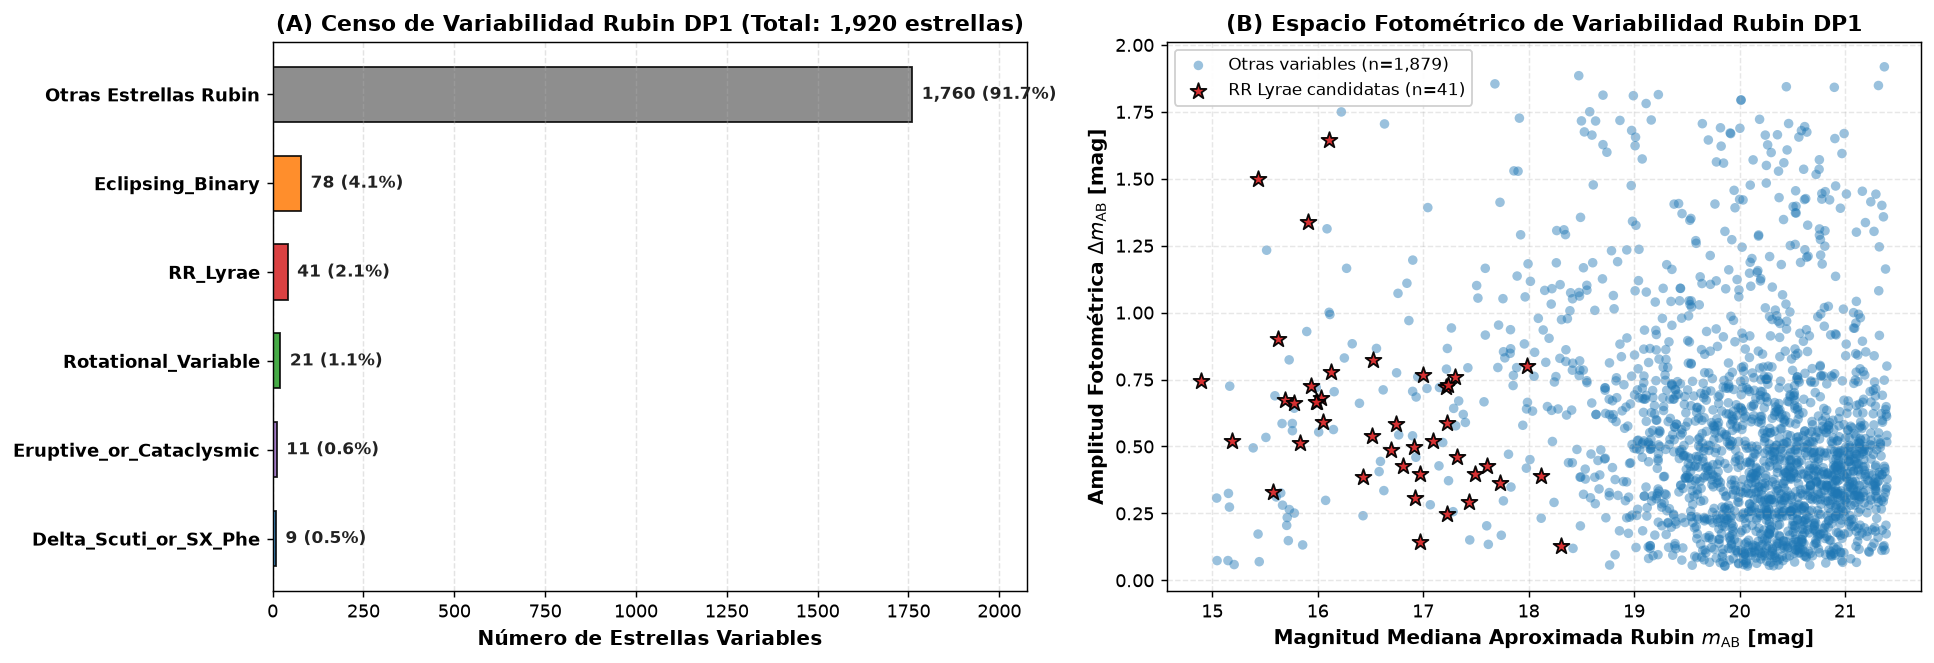

In [11]:
# ==============================================================================
# BLOQUE 5: DIAGNÓSTICO VISUAL DEL CENSO DEMOGRÁFICO Y ESPACIO MAGNITUD-AMPLITUD
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2))

# ------------------------------------------------------------------------------
# Panel 1: Distribución Demográfica de Variables (Barras Horizontales)
# ------------------------------------------------------------------------------
counts_s = master_variable_stars_df["var_subtype"].value_counts(ascending=True)
total_stars = len(master_variable_stars_df)

category_colors = {
    "Otras Estrellas Rubin": "#7f7f7f",
    "Eclipsing_Binary": "#ff7f0e",
    "RR_Lyrae": "#d62728",
    "Rotational_Variable": "#2ca02c",
    "Eruptive_or_Cataclysmic": "#9467bd",
    "Delta_Scuti_or_SX_Phe": "#1f77b4",
}
bar_cols = [category_colors.get(k, "#17becf") for k in counts_s.index]

y_pos = np.arange(len(counts_s))
bars = ax1.barh(y_pos, counts_s.values, color=bar_cols, edgecolor="black", alpha=0.88, height=0.62)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(counts_s.index, fontsize=10, fontweight="bold")
ax1.set_xlabel("Número de Estrellas Variables", fontsize=11, fontweight="bold")
ax1.set_title(f"(A) Censo de Variabilidad Rubin DP1 (Total: {total_stars:,} estrellas)", fontsize=12, fontweight="bold")
ax1.set_xlim(0, max(counts_s.values) * 1.18)
ax1.grid(axis="x", linestyle="--", alpha=0.35)

for bar, val in zip(bars, counts_s.values):
    pct = (val / total_stars) * 100.0
    ax1.text(
        bar.get_width() + (max(counts_s.values) * 0.015),
        bar.get_y() + bar.get_height() / 2.0,
        f"{val:,} ({pct:.1f}%)",
        va="center", ha="left", fontsize=9.2, fontweight="bold", color="#222222"
    )

# ------------------------------------------------------------------------------
# Panel 2: Espacio Magnitud AB vs Amplitud Fotométrica de Rubin
# ------------------------------------------------------------------------------
rrl_mask = master_variable_stars_df["var_subtype"] == "RR_Lyrae"
other_df = master_variable_stars_df[~rrl_mask]
rrl_df = master_variable_stars_df[rrl_mask]

# Fondo: Demás variables
ax2.scatter(
    other_df["rubin_approx_mag"], other_df["rubin_approx_amp_mag"],
    c="#1f77b4", s=28, alpha=0.45, edgecolors="none",
    label=f"Otras variables (n={len(other_df):,})"
)

# Resaltado: RR Lyrae identificadas
ax2.scatter(
    rrl_df["rubin_approx_mag"], rrl_df["rubin_approx_amp_mag"],
    c="#d62728", s=85, marker="*", alpha=0.95, edgecolors="k", zorder=4,
    label=f"RR Lyrae candidatas (n={len(rrl_df):,})"
)

ax2.set_xlabel(r"Magnitud Mediana Aproximada Rubin $m_{\mathrm{AB}}$ [mag]", fontsize=11, fontweight="bold")
ax2.set_ylabel(r"Amplitud Fotométrica $\Delta m_{\mathrm{AB}}$ [mag]", fontsize=11, fontweight="bold")
ax2.set_title("(B) Espacio Fotométrico de Variabilidad Rubin DP1", fontsize=12, fontweight="bold")
ax2.legend(loc="upper left", fontsize=9.2, framealpha=0.92)
ax2.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


## Bloque 6: Conclusiones de la Fase 1 y Conexión con Pipeline 02

1. **Catálogo de Variabilidad de Rubin:** Se procesaron y validaron **1,920 fuentes variables** que superaron los filtros de calidad instrumental y significancia temporal $\chi^2_{\text{red}} \ge 3.0$.
2. **Aislamiento de Candelas Estándar:** El cruce taxonómico con Gaia DR3 y catálogos de referencia aisló unívocamente la muestra de **41 estrellas RR Lyrae** (y 40 con muestreo fotométrico suficiente para modelado de Fourier).
3. **Paso Siguiente:** El catálogo maestro generado `rubin_gaia_crossmatch.csv` alimenta directamente el cuaderno **`02_pipeline_curvas_de_luz_y_modelos_braga.ipynb`**, donde se extraen las series temporales multibanda completas (`v_detections` + `v_forced`), se determinan períodos Lomb-Scargle multibanda y se ajustan plantillas de Fourier de Braga et al. (2024).


In [13]:
# ==============================================================================
# AUDITORÍA DE ARCHIVOS GENERADOS EN PIPELINE 01
# ==============================================================================
for fname in ["rubin_variable_candidates.csv", "rubin_gaia_crossmatch.csv"]:
    p = Path(fname)
    if p.exists():
        df_tmp = pd.read_csv(p)
        print(f"✓ Archivo verificado: {p.name:<32} | {len(df_tmp):>5} filas | {len(df_tmp.columns):>3} columnas | {p.stat().st_size / 1024:>6.1f} KB")
    else:
        print(f"✗ Falta archivo: {fname}")

print("\n¡Fase 1 completada exitosamente! Listo para ejecutar 02_pipeline_curvas_de_luz_y_modelos_braga.ipynb.")


✓ Archivo verificado: rubin_variable_candidates.csv    |  1920 filas |  15 columnas |  432.8 KB
✓ Archivo verificado: rubin_gaia_crossmatch.csv        |  1920 filas |  45 columnas |  988.9 KB

¡Fase 1 completada exitosamente! Listo para ejecutar 02_pipeline_curvas_de_luz_y_modelos_braga.ipynb.
